In [1]:

import pandas as pd

df = pd.read_csv("HR_Employee_Attrition_Balanced_10000_Improved.csv")

print("Dataset Shape:", df.shape)

print("\nAttrition Distribution:")
print(df["Attrition"].value_counts())

display(df.head())


Dataset Shape: (10000, 35)

Attrition Distribution:
Attrition
No     5000
Yes    5000
Name: count, dtype: int64


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,49,No,Travel_Rarely,1255,Research & Development,9,3,Life Sciences,1,300001,...,4,80,0,24,3,3,3,0,1,2
1,44,No,Travel_Rarely,1275,Research & Development,8,3,Medical,1,300002,...,3,80,0,6,2,4,3,3,0,1
2,34,Yes,Travel_Rarely,539,Sales,6,2,Life Sciences,1,300003,...,3,80,0,10,2,3,0,0,0,0
3,49,No,Travel_Rarely,1381,Sales,9,4,Marketing,1,300004,...,2,80,0,7,1,3,7,1,0,5
4,26,Yes,Travel_Rarely,389,Research & Development,3,3,Medical,1,300005,...,4,80,0,5,2,3,5,5,0,3


In [2]:

# Check data types
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       10000 non-null  int64
 1   Attrition                 10000 non-null  str  
 2   BusinessTravel            10000 non-null  str  
 3   DailyRate                 10000 non-null  int64
 4   Department                10000 non-null  str  
 5   DistanceFromHome          10000 non-null  int64
 6   Education                 10000 non-null  int64
 7   EducationField            10000 non-null  str  
 8   EmployeeCount             10000 non-null  int64
 9   EmployeeNumber            10000 non-null  int64
 10  EnvironmentSatisfaction   10000 non-null  int64
 11  Gender                    10000 non-null  str  
 12  HourlyRate                10000 non-null  int64
 13  JobInvolvement            10000 non-null  int64
 14  JobLevel                  10000 non-null  int64
 1

In [3]:

# Remove unnecessary columns
drop_cols = [
    "EmployeeNumber",
    "EmployeeCount",
    "Over18",
    "StandardHours"
]

# Features
X = df.drop(columns=drop_cols + ["Attrition"])

# Target
y = df["Attrition"].map({"No": 0, "Yes": 1})

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())


Features Shape: (10000, 30)
Target Shape: (10000,)

Target Distribution:
Attrition
0    5000
1    5000
Name: count, dtype: int64


In [4]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

print("\nTraining Distribution:")
print(y_train.value_counts())

print("\nTesting Distribution:")
print(y_test.value_counts())


Training: (8000, 30)
Testing: (2000, 30)

Training Distribution:
Attrition
0    4000
1    4000
Name: count, dtype: int64

Testing Distribution:
Attrition
0    1000
1    1000
Name: count, dtype: int64


In [6]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

# Define models
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

# Cross-Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = ["accuracy", "precision", "recall", "f1"]

# Compare models
results = []

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean(),
        "F1 Std": scores["test_f1"].std()
    })

# Display comparison
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-Score", ascending=False
)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,F1 Std
3,Gradient Boosting,0.8562,0.8576,0.8545,0.8560,0.0107
0,Logistic Regression,0.8535,0.8544,0.8525,0.8534,0.0066
2,Random Forest,0.8296,0.8371,0.8188,0.8277,0.0099
1,Decision Tree,0.7671,0.7695,0.7630,0.7660,0.0115


In [7]:

# Select the best model based on CV F1-Score
best_name = results_df.iloc[0]["Model"]

# Build final pipeline
best_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", models[best_name])
])

# Train the final model
best_pipeline.fit(X_train, y_train)

print("Best Model:", best_name)
print("Final Training Completed!")


Best Model: Gradient Boosting
Final Training Completed!


Accuracy: 0.865
Precision: 0.8614
Recall: 0.87
F1-Score: 0.8657

Classification Report:
              precision    recall  f1-score   support

          No       0.87      0.86      0.86      1000
         Yes       0.86      0.87      0.87      1000

    accuracy                           0.86      2000
   macro avg       0.87      0.86      0.86      2000
weighted avg       0.87      0.86      0.86      2000



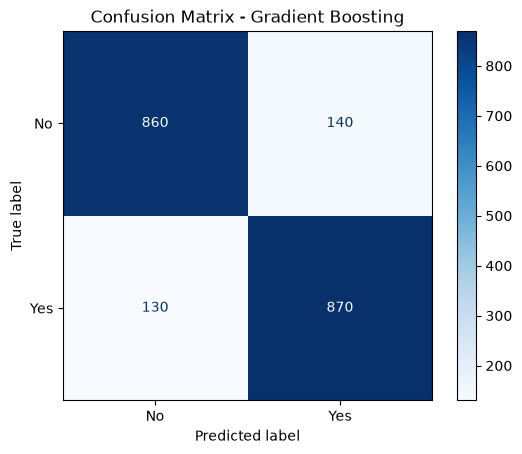

In [8]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Make predictions
y_pred = best_pipeline.predict(X_test)

# Evaluate the model
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-Score:", round(f1_score(y_test, y_pred), 4))

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No", "Yes"]
))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No", "Yes"],
    cmap="Blues",
    values_format="d"
)

plt.title(f"Confusion Matrix - {best_name}")
plt.show()


In [9]:

# Training predictions
y_train_pred = best_pipeline.predict(X_train)

# Compare performance
comparison = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Accuracy": [
        accuracy_score(y_train, y_train_pred),
        accuracy_score(y_test, y_pred)
    ],
    "F1-Score": [
        f1_score(y_train, y_train_pred),
        f1_score(y_test, y_pred)
    ]
})

display(comparison.round(4))


,Dataset,Accuracy,F1-Score
0,Training,0.8752,0.8747
1,Testing,0.8650,0.8657


In [10]:

import joblib

# Save the complete trained pipeline
joblib.dump(
    best_pipeline,
    "employee_attrition_model.pkl"
)

print("Model saved successfully!")


Model saved successfully!
